In [49]:
import torch
import torch.nn as nn
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from tqdm import tqdm
import random
import torchvision.transforms.functional as F
from PIL import Image
from utils import moving_average
from IPython.display import clear_output
import os
from glob import glob
from utils import rajouter_features

In [ ]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print(f"Using device: {device}")

# Choisir le GPU et vérifier
torch.cuda.set_device(1)
print(torch.cuda.current_device())  # doit afficher le numéro choisi dans torch.cuda.set_device()
print(torch.cuda.get_device_name(torch.cuda.current_device()))

Using device: cuda
0
Tesla V100S-PCIE-32GB


In [51]:
batch_size = 512
learning_rate = 3e-4
n_epochs = 9000 #10
crop_size = 64 #32
img_channels = 3
n_classes = 16

In [52]:
class ImageDataset(Dataset):

    def __init__(self, root_dir, transform=None):
        self.transform = transform

        # get all image paths
        self.img_paths = []

        for path in glob(os.path.join(root_dir, "**", f"*S2L2A*"), recursive=True):
            if path.lower().endswith((".jpg", ".jpeg", ".png")):

                # chemin vers l'image satellite
                img_path = path

                # chemin vers le masque de brûlé
                path_to_img_gra = img_path.replace("S2L2A", "GRA")
                path_to_img_del = img_path.replace("S2L2A", "DEL")
                if os.path.exists(path_to_img_gra):
                    img_path_burn = path_to_img_gra
                elif os.path.exists(path_to_img_del):
                    img_path_burn = path_to_img_del
                else:
                    print("********** image brûlée non trouvée *********")
                    continue

                # chemin vers l'image annotée
                img_ann_path = img_path.replace("S2L2A", "Esri10_LC")
                assert os.path.exists(img_ann_path), f"Annotation image not found: {img_ann_path}"

                self.img_paths.append((img_path, img_path_burn, img_ann_path))

        # loads images into memory
        self.data = []

        for img_path, img_path_burn, img_ann_path in tqdm(self.img_paths):
            img = Image.open(img_path).convert("RGB")
            img_ann = Image.open(img_ann_path).convert("RGB")
            img_burn = Image.open(img_path_burn).convert("RGB")
            img_ann = rajouter_features(img_ann, img_burn)   # rajouter les features artificielles aux annotations
            assert img.size == img_ann.size, f"Image size mismatch: {img_path} and {img_ann_path}"
            img_tensor = transforms.ToTensor()(img)
            img_ann_tensor = transforms.ToTensor()(img_ann)
            self.data.append((img_tensor, img_ann_tensor))

        print(f"[INFO] Dataset chargé en mémoire : {len(self.data)} images, "
              f"{sum(img[0].element_size() * img[0].nelement() for img in self.data) / 1e6:.1f} Mo RAM")


    def __len__(self):
        return len(self.img_paths)


    def random_crop(self, img, img_ann):
        _, h, w = img.shape

        assert img.shape == img_ann.shape, "Les images doivent avoir la même forme"

        if crop_size > h or crop_size > w:
            raise ValueError("Le crop est plus grand que l'image")

        top = torch.randint(0, h - crop_size + 1, (1,)).item()
        left = torch.randint(0, w - crop_size + 1, (1,)).item()

        cropped = img[:, top:top+crop_size, left:left+crop_size]
        cropped_ann = img_ann[:, top:top+crop_size, left:left+crop_size]

        return cropped, cropped_ann
    

    def data_augm_pair(self, img1, img2):
        # flip horizontal
        if random.random() > 0.5:
            img1 = F.hflip(img1)
            img2 = F.hflip(img2)

        # flip vertical
        if random.random() > 0.5:
            img1 = F.vflip(img1)
            img2 = F.vflip(img2)

        # rotation
        angles = [0, 90, 180, 270]
        angle = random.choice(angles)
        img1 = F.rotate(img1, angle)
        img2 = F.rotate(img2, angle)

        return img1, img2


    def __getitem__(self, idx):
        img_tensor, img_ann_tensor = self.data[idx]

        cropped_tensor, cropped_tensor_ann = self.random_crop(img_tensor, img_ann_tensor)

        if self.transform:
            cropped_tensor = self.transform(cropped_tensor)
            cropped_tensor, cropped_tensor_ann = self.data_augm_pair(cropped_tensor, cropped_tensor_ann)

        return cropped_tensor, cropped_tensor_ann


transform = transforms.Compose([
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

train_dataset = ImageDataset(root_dir="data/dataset/train", transform=transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)

val_dataset = ImageDataset(root_dir="data/dataset/val", transform=transform)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=True, num_workers=0)

train_iterator = iter(train_loader)
val_iterator = iter(val_loader)

100%|██████████| 281/281 [00:58<00:00,  4.78it/s]


[INFO] Dataset chargé en mémoire : 281 images, 5722.9 Mo RAM


100%|██████████| 53/53 [00:11<00:00,  4.55it/s]

[INFO] Dataset chargé en mémoire : 53 images, 1246.7 Mo RAM


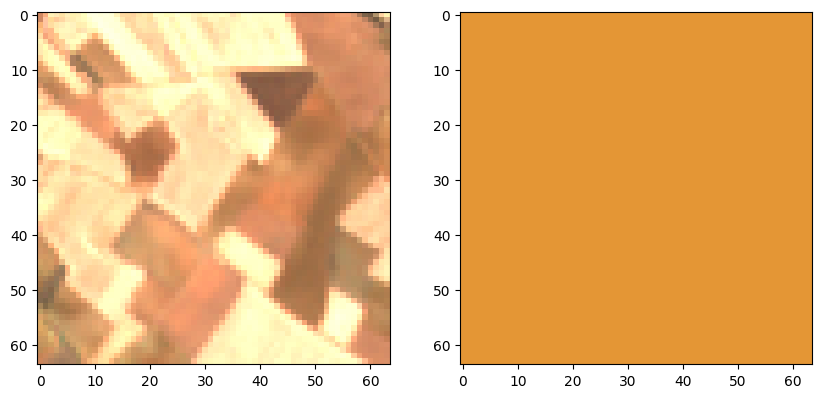

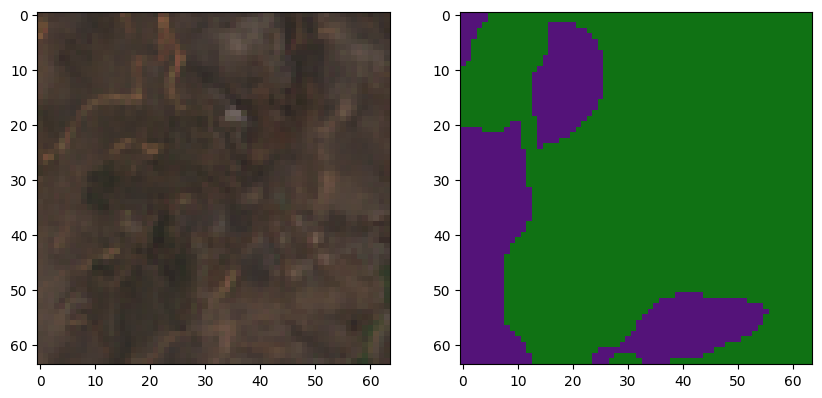

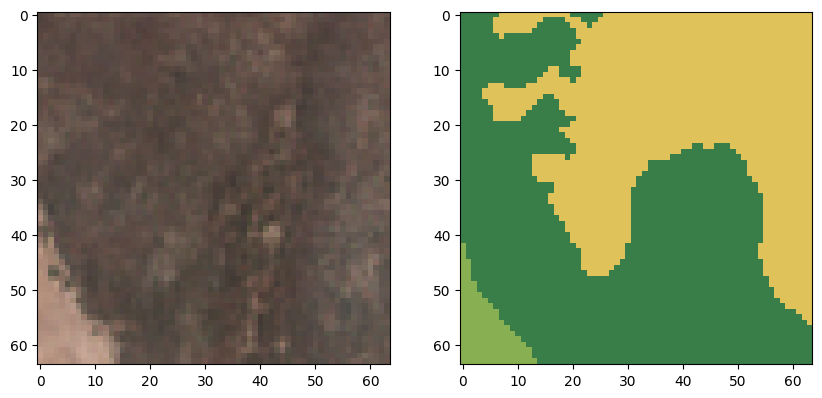

In [ ]:
for i in range(3):
    img1, img2, *_ = next(iter(train_loader)) 

    # On prend le premier élément du batch
    img1 = img1[0].permute(1, 2, 0).numpy()
    img2 = img2[0].permute(1, 2, 0).numpy()

    # Les images sont souvent normalisées, on remet dans [0,1]
    img1 = (img1 + 1) / 2

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(img1)
    plt.subplot(1, 2, 2)
    plt.imshow(img2)
    plt.show()

In [54]:
from torchvision.models import resnet18
from torchvision.models import ResNet18_Weights   # Import des poids officiels

resnet = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)   # Charger un modèle préentraîné

# checkpoint = torch.load("weights/resnet_sur_crops_sat_32x32_checkpoint10.pth")
# state_dict = checkpoint['model_state_dict']
# state_dict.pop('fc.weight')   # on ne charge pas les poids de la dernière couche car elle est différente
# state_dict.pop('fc.bias')
# resnet.load_state_dict(state_dict, strict=False)  # strict=False ignore les paramètres manquants

encoder = nn.Sequential(*list(resnet.children())[:-2])    # enlever les couches avgpool : AdaptiveAvgPool2d(output_size=(1, 1)) et fc : Linear(in_features=512, out_features=1000, bias=True)

decoder = nn.Sequential(
    # nn.Dropout2d(p=0.2),  # Dropout pour éviter le surapprentissage
    nn.ConvTranspose2d(in_channels=512, out_channels=n_classes, kernel_size=32, stride=32)  # stride=32 pour remonter de H/32 -> H
)

# decoder = nn.Sequential(
#     nn.Upsample(scale_factor=32, mode="bilinear"),
#     nn.Conv2d(512, n_classes, kernel_size=1)
# )

model = nn.Sequential(
    encoder,
    decoder
)

# # différentes couches du modèle
# for name, layer in model.named_children():
#     print(name, ":", layer)

In [ ]:
model = model.to(device)   # model.to(device) et pas model().to(device) car ici le model est déjà instancié
# optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, fused=True)   #, weight_decay=1e-4)
optimizer = torch.optim.AdamW(decoder.parameters(), lr=learning_rate, fused=True)
criterion = nn.CrossEntropyLoss()

total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters in the model: {total_params/1e6:.6f} million")

train_loss_list, val_loss_list = [], []
train_iou_list, val_iou_list = [], []

Total parameters in the model: 19.565136 million


In [56]:
def imgs_to_niveaucouleur(imgs):

    imgs = (imgs * 255).byte()

    imgs = imgs.permute(1, 0, 2, 3)   # (B, C, H, W) -> (C, B, H, W)

    colors = [[57, 125, 73], [65, 155, 223], [122, 135, 198], [136, 176, 83], [196, 40, 27], [223, 195, 90], [228, 150, 53], [13, 253, 21], [165, 244, 167], [65, 166, 68], [16, 114, 20], [242, 34, 214], [207, 128, 253], [145, 64, 206], [84, 19, 121]]

    masks = []
    for c in colors:
        color_tensor = torch.tensor(c, dtype=imgs.dtype, device=imgs.device).view(-1, 1, 1, 1)
        mask = (imgs == color_tensor).all(dim=0)
        masks.append(mask)

    # # Combiner tous les masks
    # combined_mask = masks[0].clone()
    # for m in masks[1:]:
    #     combined_mask |= m  # ou “torch.logical_or(combined_mask, m)”

    # # Vérifier les pixels qui ne correspondent à aucune couleur
    # unknown_pixels = ~combined_mask
    # n_unknown = unknown_pixels.sum().item()

    # print(f"Nombre de pixels inconnus : {n_unknown}")

    out = torch.zeros((imgs.shape[1], imgs.shape[2], imgs.shape[3]), dtype=torch.int64, device=imgs.device)
    for i, mask in enumerate(masks):
        out[mask] = i + 1

    return out

In [57]:
def get_IoUs(preds, targets):
    ious = []
    preds = preds.view(-1)
    targets = targets.view(-1)

    for cls in range(n_classes):
        pred_inds = (preds == cls)
        target_inds = (targets == cls)

        intersection = (pred_inds & target_inds).sum().item()
        union = (pred_inds | target_inds).sum().item()

        if union == 0:
            ious.append(float('nan'))  # classe absente, diviser par "nan" donne un "nan"
        else:
            ious.append(intersection / union)
    
    return ious

In [ ]:
def ious_plots(train_ious_list, val_ious_list, w=3):

    # Transposer la liste pour avoir une liste par classe
    train_ious_per_class = list(zip(*train_ious_list))
    val_ious_per_class = list(zip(*val_ious_list))

    fig, axes = plt.subplots(4, 4, figsize=(20, 20))
    axes = axes.flatten()  # pour itérer facilement même si certaines cases restent vides


    for i in range(len(train_ious_per_class)):
        train_ious = train_ious_per_class[i]
        val_ious = val_ious_per_class[i]
        train_ious_smoothed = moving_average(train_ious, w=w)
        val_ious_smoothed = moving_average(val_ious, w=w)

        ax = axes[i]
        ax.plot(train_ious, alpha=0.2, color="blue")
        ax.plot(train_ious_smoothed, linestyle='--', color="blue")
        ax.plot(val_ious, alpha=0.2, color="red")
        ax.plot(val_ious_smoothed, linestyle='--', color="red")
        ax.set_title(f"Classe {i}")
        ax.grid(True, linestyle='--', alpha=0.3)

    plt.tight_layout()
    plt.show()


moyenne sur les 100 dernières valeurs:   train_loss: 0.6623328924179077   val_loss: 1.1011146306991577   train_iou_loss: 0.46121346950531006   val_iou_loss: 0.2539503872394562


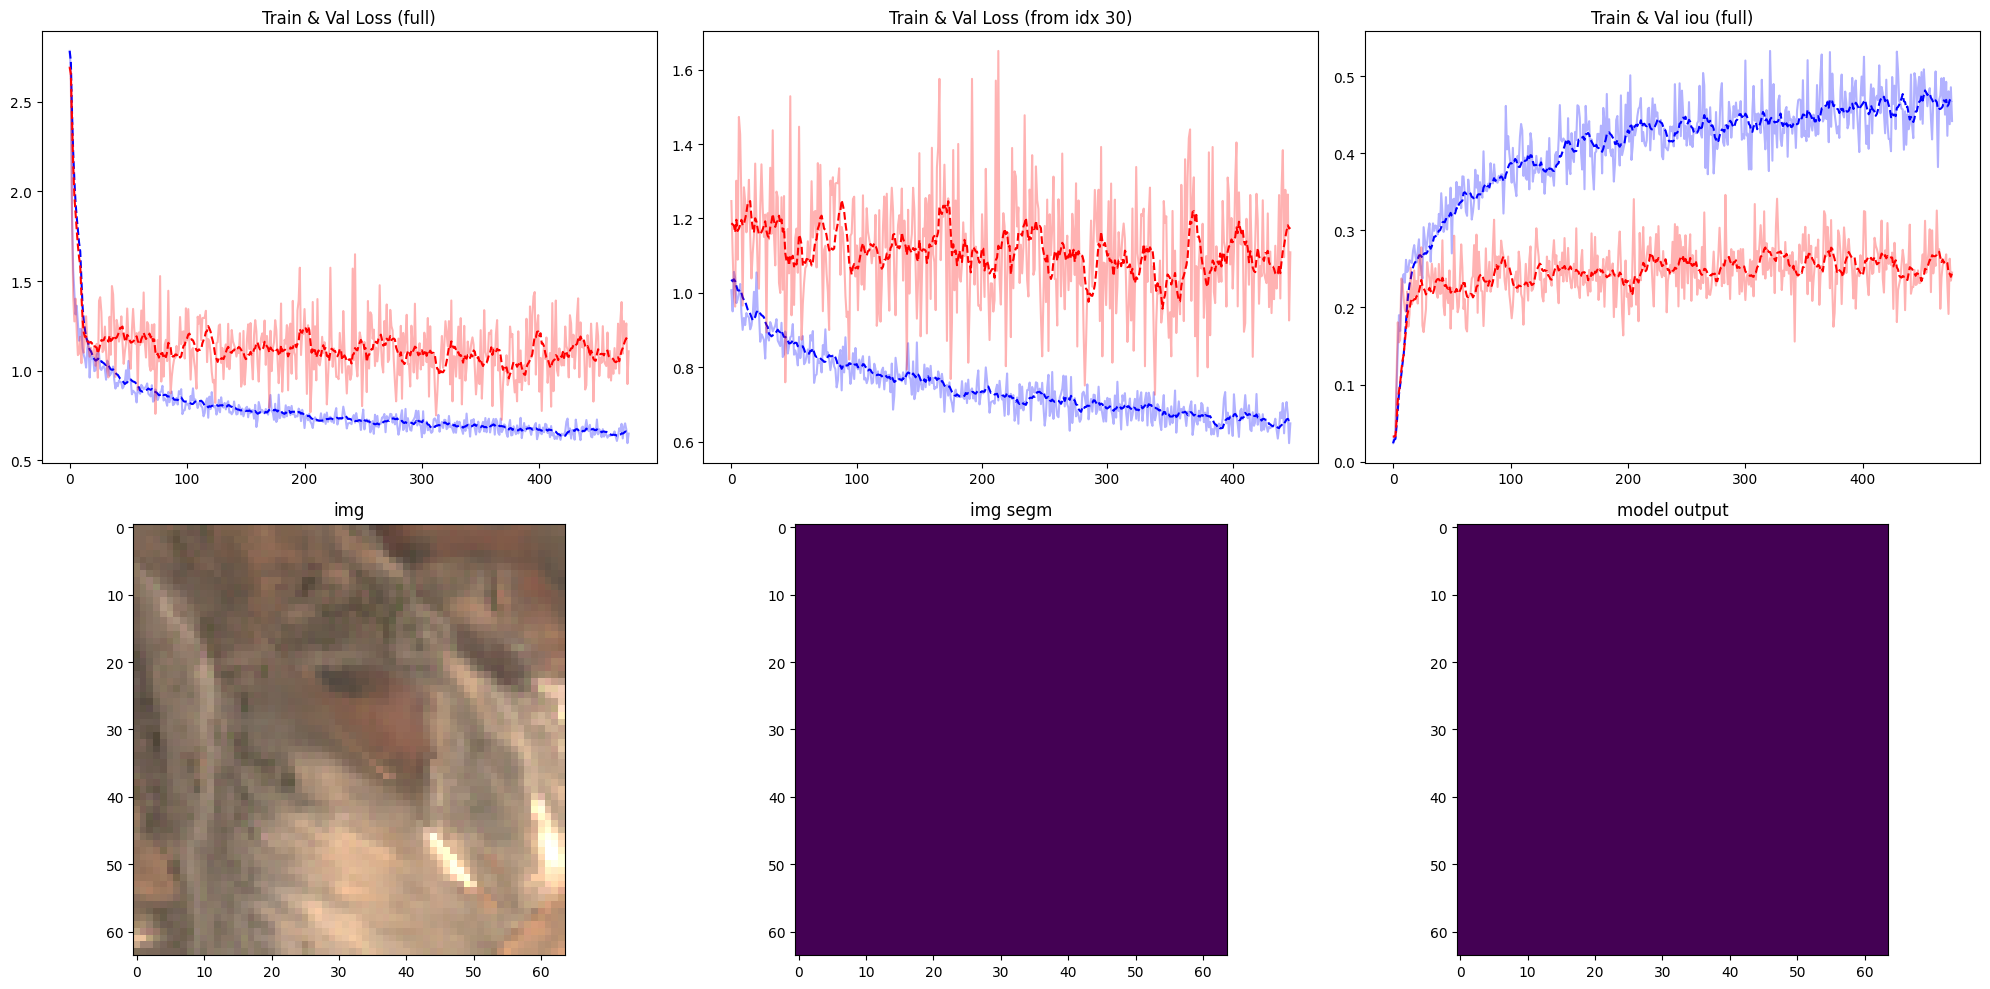

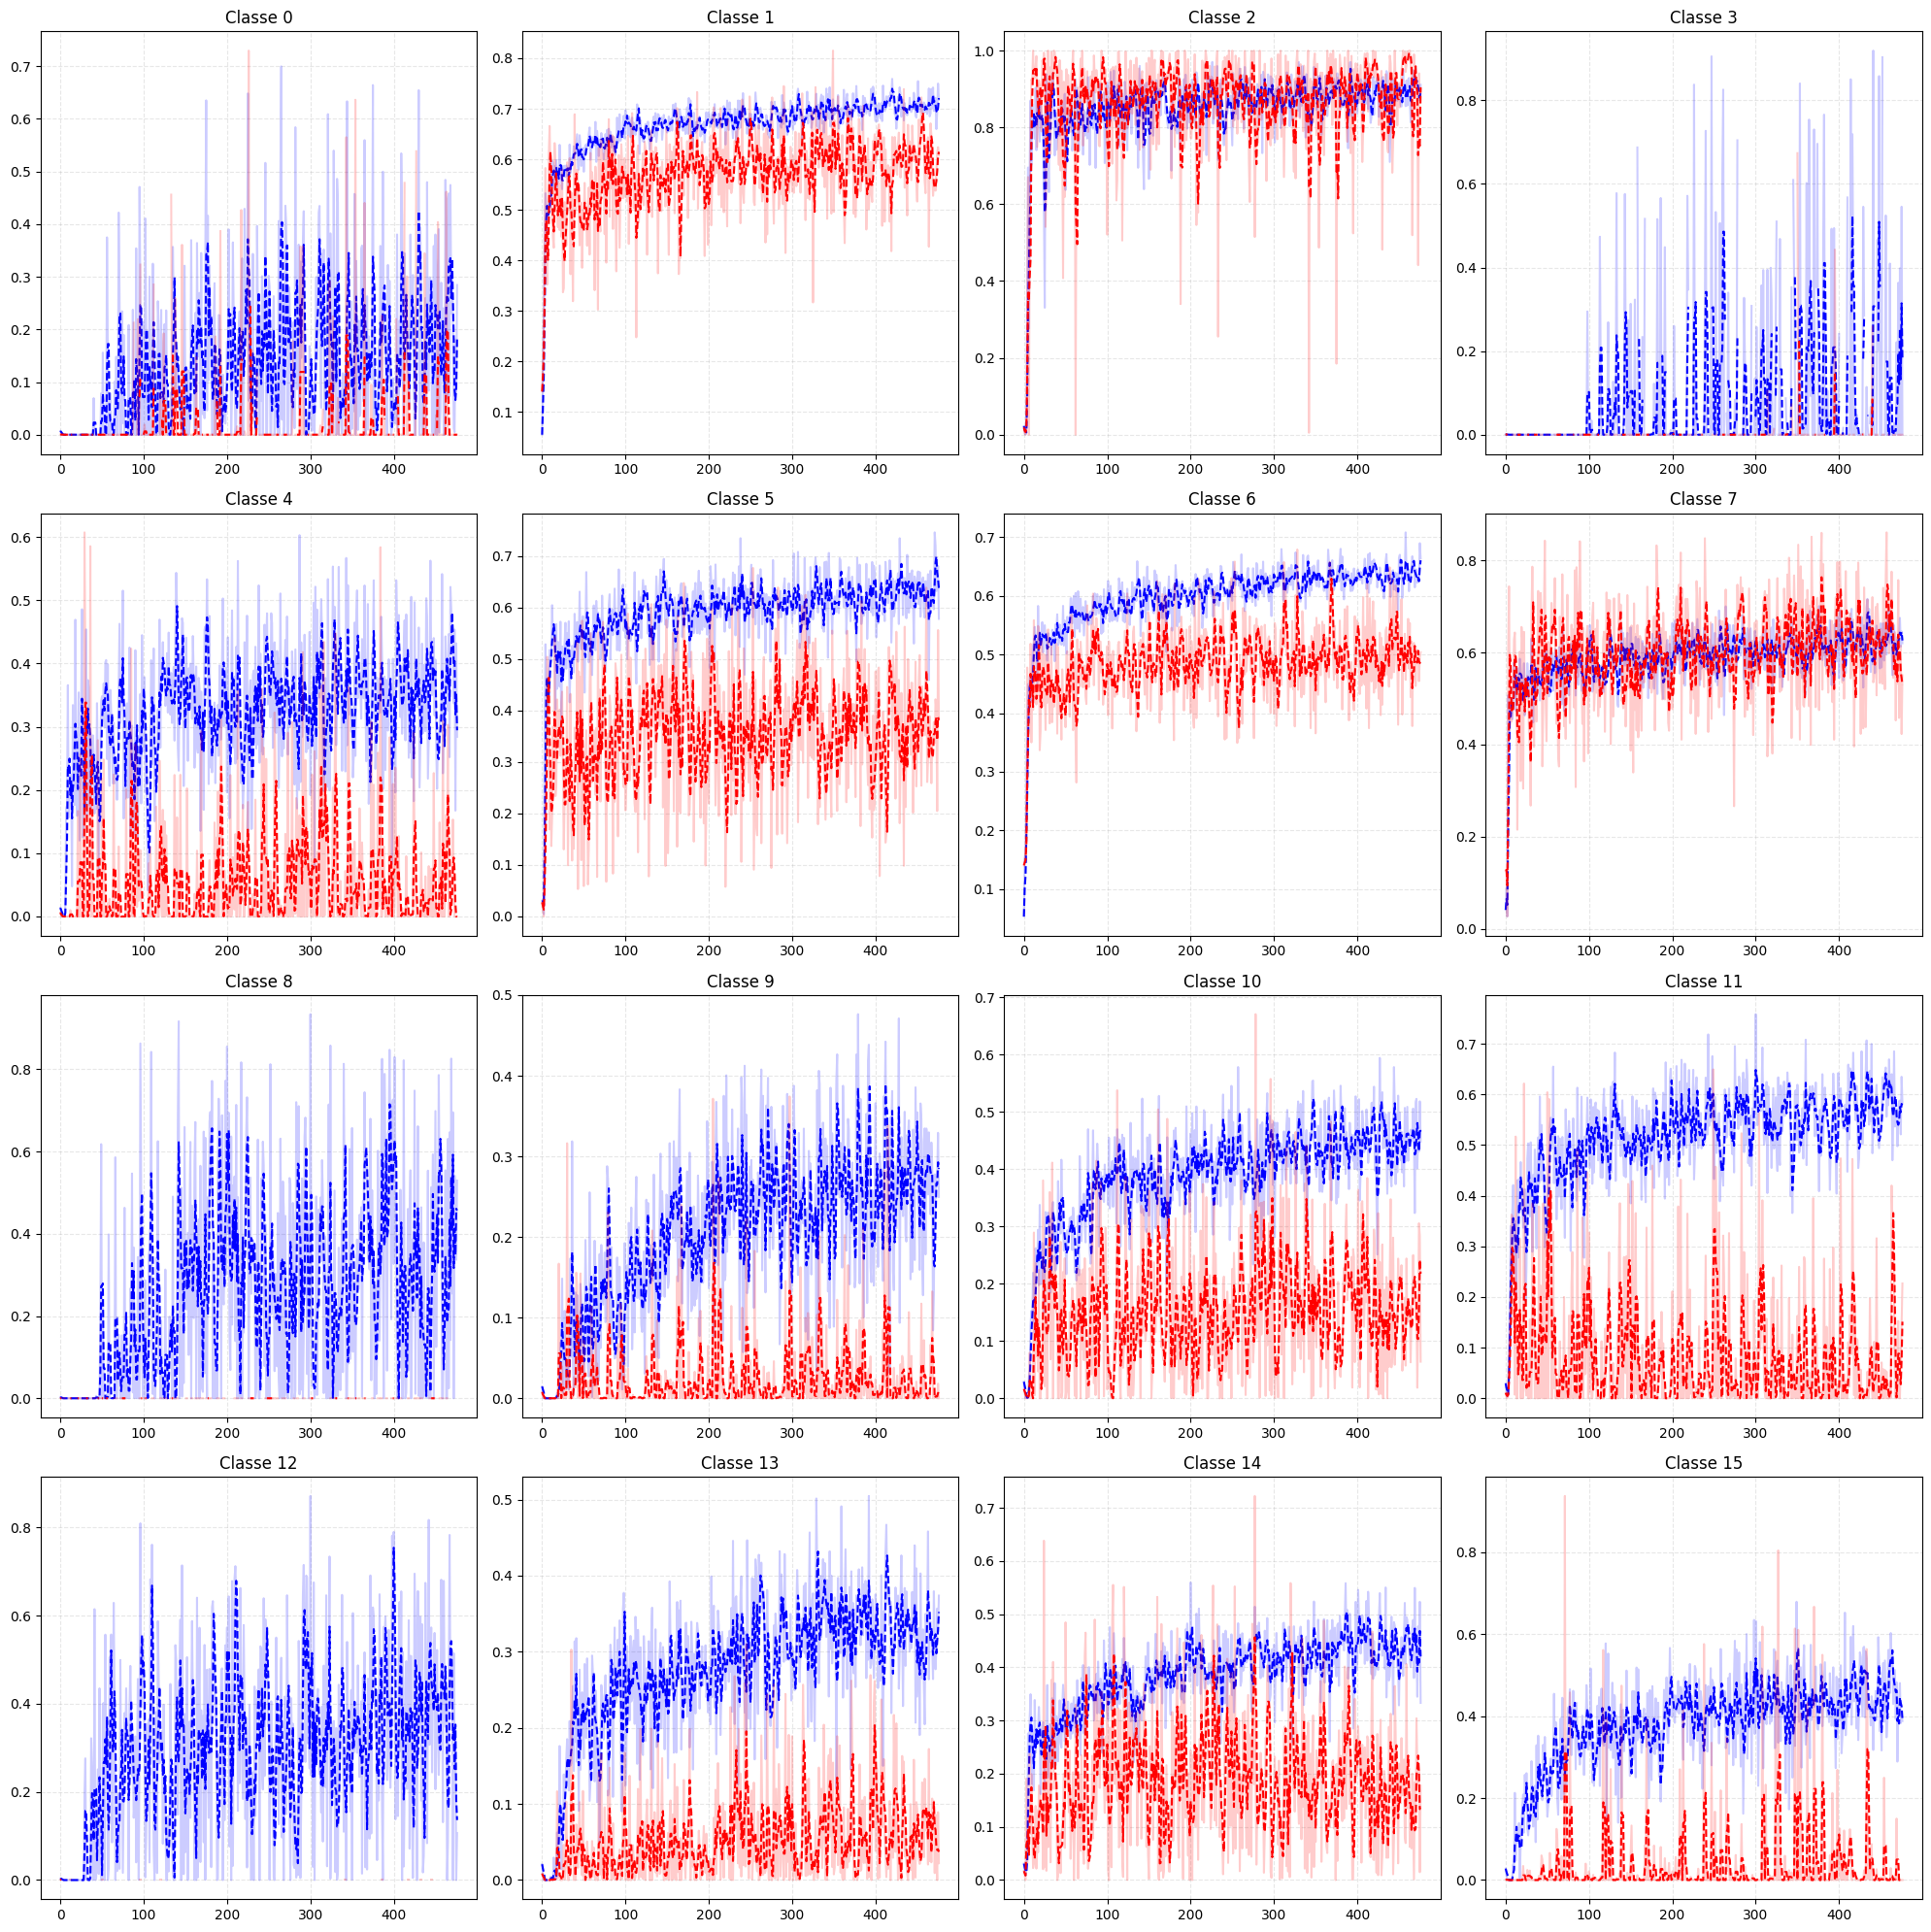

 33%|███▎      | 3005/9000 [31:15<1:02:21,  1.60it/s] 


KeyboardInterrupt: 

In [102]:
for epoch in tqdm(range(n_epochs)):
    for i, (imgs, imgs_segm) in enumerate(train_loader):

        imgs, imgs_segm = imgs.to(device), imgs_segm.to(device)
        imgs_segm = imgs_to_niveaucouleur(imgs_segm)

        output = model(imgs)
        loss = criterion(output, imgs_segm)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()



        if epoch % 10 == 0 and i % 999 == 0:
        # if i % 10 == 0:

            train_loss_list.append(loss.item())

            # get train iou score
            with torch.no_grad():
                preds = output.argmax(dim=1)  # prendre la classe avec la probabilité la plus élevée
                ious = get_IoUs(preds, imgs_segm)
                train_iou_list.append(ious)

            # get val loss & val iou score
            model.eval()
            with torch.no_grad():
                try:
                    imgs, imgs_segm = next(val_iterator)
                except StopIteration:
                    val_iterator = iter(val_loader)
                    imgs, imgs_segm = next(val_iterator)
                imgs, imgs_segm = imgs.to(device), imgs_segm.to(device)
                imgs_segm = imgs_to_niveaucouleur(imgs_segm)
                output = model(imgs)
                val_loss = criterion(output, imgs_segm)
                val_loss_list.append(val_loss.item())

                preds = output.argmax(dim=1)  # prendre la classe avec la probabilité la plus élevée
                ious = get_IoUs(preds, imgs_segm)
                val_iou_list.append(ious)
            model.train()



    if epoch % 900 == 0:
    # if epoch % 1 == 0:

        train_iou_list_mean = torch.tensor(train_iou_list).nanmean(dim=1).tolist()
        val_iou_list_mean = torch.tensor(val_iou_list).nanmean(dim=1).tolist()

        train_loss_list_smoothed = moving_average(train_loss_list)
        val_loss_list_smoothed = moving_average(val_loss_list)
        train_iou_list_mean_smoothed = moving_average(train_iou_list_mean)
        val_iou_list_mean_smoothed = moving_average(val_iou_list_mean)

        clear_output(wait=True)  # efface l'ancien plot

        print(f"moyenne sur les 100 dernières valeurs:   train_loss: {torch.tensor([train_loss_list[-100:]]).mean()}   val_loss: {torch.tensor([val_loss_list[-100:]]).mean()}   train_iou_loss: {torch.tensor([train_iou_list[-100:]]).nanmean()}   val_iou_loss: {torch.tensor([val_iou_list[-100:]]).nanmean()}")

        imgs, imgs_segm = next(iter(train_loader))
        imgs_segm = imgs_to_niveaucouleur(imgs_segm)
        output = model(imgs.to(device))
        output = output.argmax(dim=1).cpu()  # prendre la classe avec la probabilité la plus élevée

        plt.figure(figsize=(20, 10))

        plt.subplot(2, 3, 1)
        plt.plot(train_loss_list, c="blue", alpha=0.3)
        plt.plot(train_loss_list_smoothed, c="blue", linestyle='--')
        plt.plot(val_loss_list, c="red", alpha=0.3)
        plt.plot(val_loss_list_smoothed, c="red", linestyle='--')
        plt.title("Train & Val Loss (full)")

        plt.subplot(2, 3, 2)
        plt.plot(train_loss_list[30:], c="blue", alpha=0.3)
        plt.plot(train_loss_list_smoothed[30:], c="blue", linestyle='--')
        plt.plot(val_loss_list[30:], c="red", alpha=0.3)
        plt.plot(val_loss_list_smoothed[30:], c="red", linestyle='--')
        plt.title("Train & Val Loss (from idx 30)")

        plt.subplot(2, 3, 3)
        plt.plot(train_iou_list_mean, c="blue", alpha=0.3)
        plt.plot(train_iou_list_mean_smoothed, c="blue", linestyle='--')
        plt.plot(val_iou_list_mean, c="red", alpha=0.3)
        plt.plot(val_iou_list_mean_smoothed, c="red", linestyle='--')
        plt.title("Train & Val iou (full)")

        plt.subplot(2, 3, 4)
        plt.imshow((imgs[0].permute(1, 2, 0)+1)/2)
        plt.title("img")

        plt.subplot(2, 3, 5)
        plt.imshow(imgs_segm[0])
        plt.title("img segm")

        plt.subplot(2, 3, 6)
        plt.imshow(output[0])
        plt.title("model output")

        plt.tight_layout()  # ajuste l'espacement
        plt.show()

        ious_plots(train_iou_list, val_iou_list)

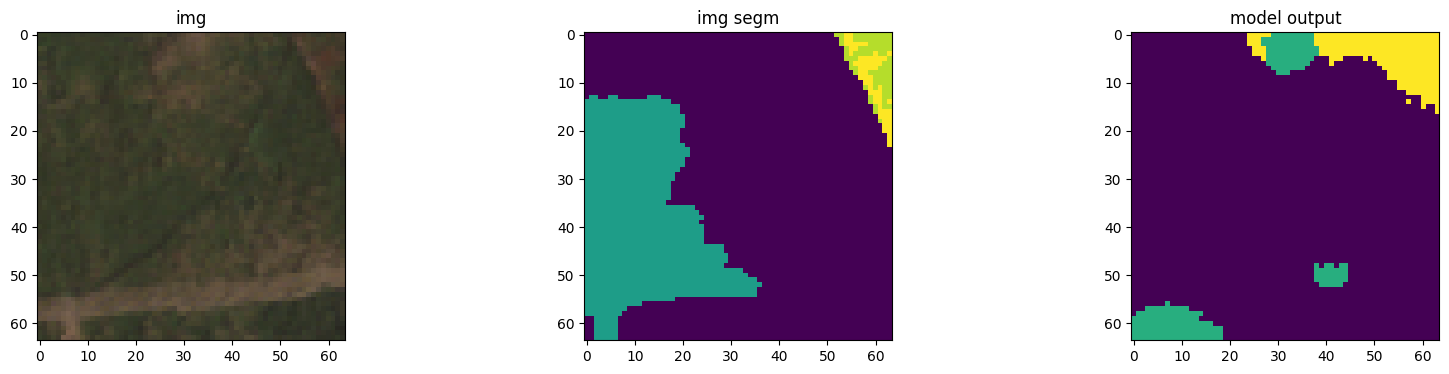

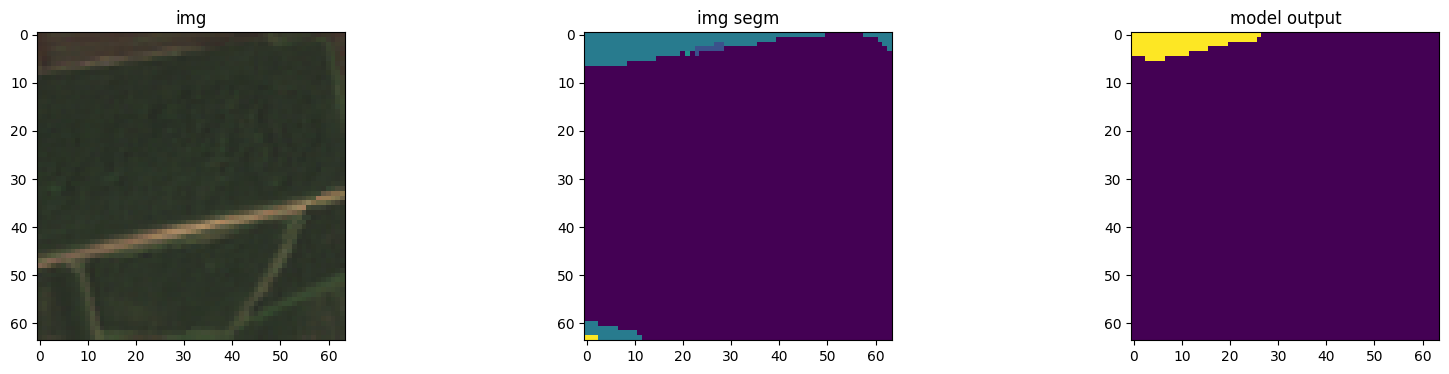

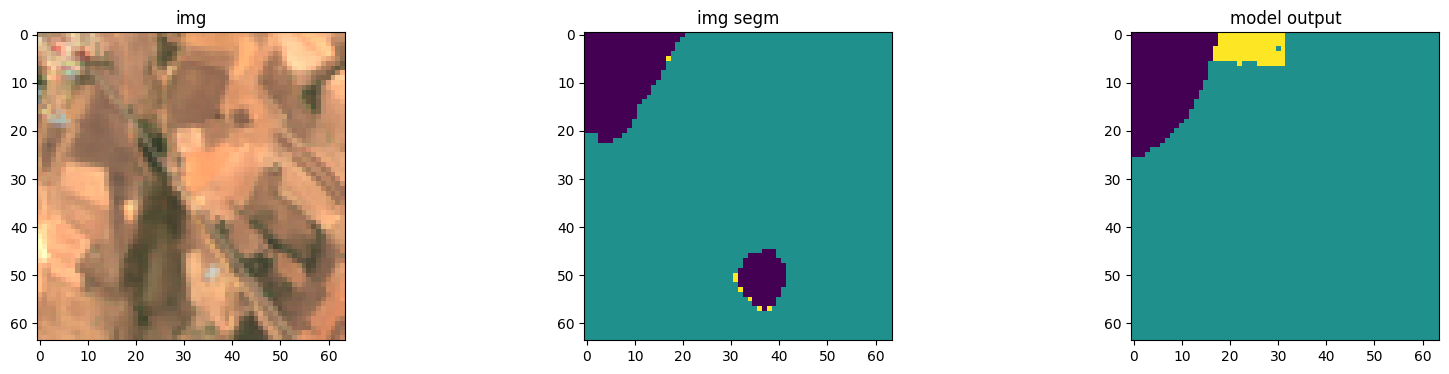

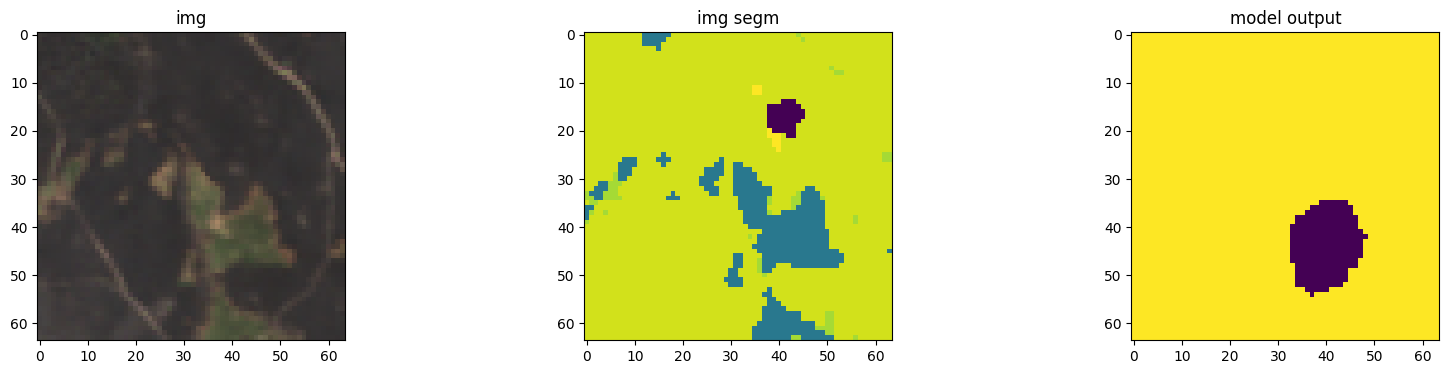

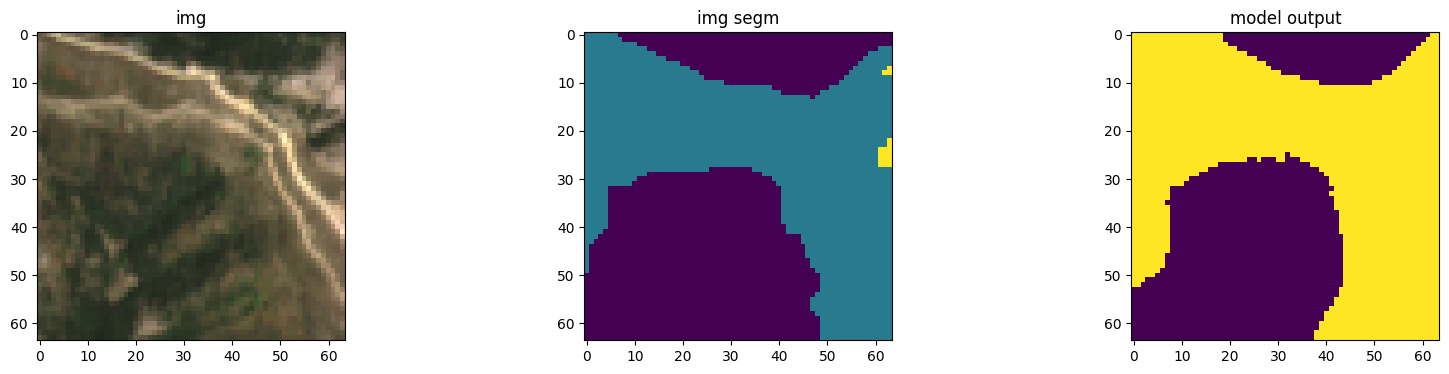

In [28]:
imgs, imgs_segm = next(iter(train_loader))
imgs_segm = imgs_to_niveaucouleur(imgs_segm)
output = model(imgs.to(device))
output = output.argmax(dim=1).cpu()  # prendre la classe avec la probabilité la plus élevée

for i in range(5):
    plt.figure(figsize=(20, 4))
    plt.subplot(1, 3, 1)
    plt.imshow((imgs[i].permute(1, 2, 0)+1)/2)
    plt.title("img")
    plt.subplot(1, 3, 2)
    plt.imshow(imgs_segm[i])
    plt.title("img segm")
    plt.subplot(1, 3, 3)
    plt.imshow(output[i])
    plt.title("model output")
    plt.show()